# Laboratório 1 — Modelo de Probabilidade Linear

**Econometria I · Capítulo 15 · Aula 1 de 5 · 60 minutos**

**Pergunta da aula:** como o desempenho anterior e a participação em um método de ensino se relacionam com a probabilidade de um estudante obter conceito A?

Ao final, você deverá conseguir estimar um modelo de probabilidade linear (MPL), interpretar seus coeficientes em pontos percentuais e reconhecer suas principais limitações.

**Leitura:** Gujarati e Porter, *Econometria básica*, 5ª edição, capítulo 15, especialmente as seções 15.1–15.4. Usaremos os dados da Tabela 15.7 (p. 559) e reproduziremos o MPL da Tabela 15.14 (p. 567). Essas tabelas aparecem adiante no mesmo capítulo; nesta aula estimaremos apenas o MPL.

| Tempo | Etapa |
|---|---|
| 0–5 min | Abrir o notebook e apresentar a pergunta |
| 5–15 min | Conhecer os dados e interpretar uma variável binária |
| 15–25 min | Estimar e interpretar o MPL |
| 25–35 min | Fazer previsões e examinar os limites do modelo |
| 35–40 min | Comparar erros padrão usuais e robustos |
| 40–55 min | Resolver o exercício em duplas |
| 55–60 min | Discutir as conclusões |

## Antes de começar · 0–5 min

1. Abra [Google Colab](https://colab.research.google.com/), escolha **Arquivo → Fazer upload de notebook** e selecione este arquivo `.ipynb` (o nome do menu pode aparecer em inglês).
2. Salve uma cópia para registrar suas alterações. Execute as células de código na ordem, usando o botão ▶ ou **Shift + Enter**.
3. Nas células de texto marcadas **Sua resposta**, dê dois cliques para escrever sua interpretação.

Os dados estão incorporados abaixo: não é necessário montar o Drive nem baixar uma planilha. As células do exercício indicam o que preencher e podem ser executadas sem preenchimento, sem interromper o notebook.

**Para a discussão inicial:** quando o resultado só pode ser 0 ou 1, o que seria útil prever antes de conhecê-lo?

In [1]:
# Bibliotecas: tabelas, cálculos, gráficos e estimação econométrica.
# O Colab normalmente já oferece essas bibliotecas.
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("statsmodels") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "statsmodels"])

from io import StringIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display

%matplotlib inline
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 10)
print("Ambiente pronto. Vamos trabalhar com os 32 estudantes da Tabela 15.7.")

Ambiente pronto. Vamos trabalhar com os 32 estudantes da Tabela 15.7.


## 1. Dados e significado da variável dependente · 5–15 min

A base contém 32 estudantes do estudo de Spector e Mazzeo (1980), utilizado no livro.

| Variável | Significado nesta aula |
|---|---|
| `Y` | 1 se o conceito final foi A; 0 se foi B ou C |
| `GPA` | Média de pontos do estudante no início do curso |
| `TUCE` | Pontuação em uma prova de conhecimentos de economia aplicada no início do semestre |
| `PSI` | 1 se o estudante participou do novo método de ensino; 0 caso contrário |

Seguimos a definição de `Y` da Tabela 15.7. A base também é distribuída pelo pacote `statsmodels` com o nome `spector`; aqui os valores estão escritos no próprio notebook para que a atividade não dependa de um endereço de dados.

**Antes de estimar:** qual sinal você esperaria para cada variável? Qual é a justificativa?

In [2]:
# Valores da Tabela 15.7. Cada linha representa um estudante.
csv_estudantes = """GPA,TUCE,PSI,Y
2.66,20,0,0
2.89,22,0,0
3.28,24,0,0
2.92,12,0,0
4.00,21,0,1
2.86,17,0,0
2.76,17,0,0
2.87,21,0,0
3.03,25,0,0
3.92,29,0,1
2.63,20,0,0
3.32,23,0,0
3.57,23,0,0
3.26,25,0,1
3.53,26,0,0
2.74,19,0,0
2.75,25,0,0
2.83,19,0,0
3.12,23,1,0
3.16,25,1,1
2.06,22,1,0
3.62,28,1,1
2.89,14,1,0
3.51,26,1,0
3.54,24,1,1
2.83,27,1,1
3.39,17,1,1
2.67,24,1,0
3.65,21,1,1
4.00,23,1,1
3.10,21,1,0
2.39,19,1,1
"""

dados = pd.read_csv(StringIO(csv_estudantes))
dados.index = pd.RangeIndex(1, len(dados) + 1, name="Estudante")
print(f"Número de estudantes: {len(dados)}")
display(dados.head(6))

Número de estudantes: 32


,GPA,TUCE,PSI,Y
Estudante,,,,
1,2.66,20,0,0
2,2.89,22,0,0
3,3.28,24,0,0
4,2.92,12,0,0
5,4.00,21,0,1
6,2.86,17,0,0


### Por que a média de uma variável binária é uma proporção?

Se há 11 estudantes com `Y = 1` entre 32 estudantes, a média de `Y` é a proporção que obteve A. Condicionalmente aos regressores, vale a mesma ideia:

$$
E(Y_i\mid X_i)=1\times P(Y_i=1\mid X_i)+0\times P(Y_i=0\mid X_i)
=P(Y_i=1\mid X_i)=p_i.
$$

Portanto, modelar a média condicional de uma variável binária equivale a modelar uma probabilidade.

In [3]:
print(f"Estudantes com conceito A: {dados['Y'].sum()}")
print(f"Proporção com conceito A: {dados['Y'].mean():.2%}")

# Comparação descritiva entre os dois grupos de ensino.
por_metodo = dados.groupby("PSI").agg(
    estudantes=("Y", "size"),
    proporcao_A=("Y", "mean"),
    GPA_medio=("GPA", "mean"),
    TUCE_medio=("TUCE", "mean"),
)
display(por_metodo.style.format({
    "proporcao_A": "{:.2%}", "GPA_medio": "{:.2f}", "TUCE_medio": "{:.2f}"
}))

Estudantes com conceito A: 11
Proporção com conceito A: 34.38%


,estudantes,proporcao_A,GPA_medio,TUCE_medio
PSI,,,,
0,18,16.67%,3.10,21.56
1,14,57.14%,3.14,22.43


**Pare e interprete:** a diferença bruta entre os grupos `PSI = 0` e `PSI = 1` compara estudantes com o mesmo GPA e TUCE? A regressão permitirá calcular uma diferença ajustada por essas duas características. Uma associação estimada, por si só, não estabelece um efeito causal.

## 2. Estimando o MPL por MQO · 15–25 min

Vamos estimar:

$$
Y_i=\beta_1+\beta_2 GPA_i+\beta_3 TUCE_i+\beta_4 PSI_i+u_i.
$$

Sob a hipótese de média condicional zero do erro, a especificação implica:

$$
p_i=E(Y_i\mid GPA_i,TUCE_i,PSI_i)
=\beta_1+\beta_2 GPA_i+\beta_3 TUCE_i+\beta_4 PSI_i.
$$

O procedimento de MQO é o que já conhecemos. A novidade é a interpretação da variável dependente. **O MPL supõe que a probabilidade varie linearmente com os regressores.**

No código, `add_constant` inclui o intercepto; `OLS` define a regressão por MQO; `fit()` estima os coeficientes.

In [4]:
regressores = ["GPA", "TUCE", "PSI"]
X = sm.add_constant(dados[regressores], has_constant="add")
y = dados["Y"]

mpl = sm.OLS(y, X).fit()

tabela_mqo = pd.DataFrame({
    "Coeficiente": mpl.params,
    "Erro padrão usual": mpl.bse,
    "p-valor usual": mpl.pvalues,
})
display(tabela_mqo.style.format("{:.4f}"))
print(f"Observações: {int(mpl.nobs)} | R²: {mpl.rsquared:.4f}")

Observações: 32 | R²: 0.4159


,Coeficiente,Erro padrão usual,p-valor usual
const,-1.4980,0.5239,0.0079
GPA,0.4639,0.1620,0.0078
TUCE,0.0105,0.0195,0.5944
PSI,0.3786,0.1392,0.0111


### Como ler os coeficientes

Os coeficientes reproduzem, por arredondamento, a Tabela 15.14:

$$
\widehat p_i\approx-1{,}4980+0{,}4639\,GPA_i+0{,}0105\,TUCE_i+0{,}3786\,PSI_i.
$$

- **GPA:** uma unidade adicional está associada a aproximadamente 46,39 **pontos percentuais** a mais na probabilidade prevista, mantendo TUCE e PSI constantes. Para outra variação de GPA, multiplique o coeficiente por essa variação.
- **TUCE:** um ponto adicional está associado a aproximadamente 1,05 ponto percentual a mais, mantendo os demais regressores constantes.
- **PSI:** passar de 0 para 1 está associado a uma diferença ajustada de aproximadamente 37,86 pontos percentuais.

O intercepto corresponde a GPA = TUCE = PSI = 0, um perfil fora do suporte destes dados; não oferece uma interpretação substantiva útil aqui.

**Atenção à unidade:** mudar de 20% para 30% representa 10 pontos percentuais. A variação percentual relativa seria 50%. Na interpretação do MPL, usamos a primeira medida.

In [5]:
# Exemplo resolvido: um aumento de 0,1 ponto no GPA.
delta_gpa_exemplo = 0.1
delta_p_exemplo = mpl.params["GPA"] * delta_gpa_exemplo
print(f"Aumento de {delta_gpa_exemplo} no GPA: {100 * delta_p_exemplo:.2f} pontos percentuais.")
print(f"Mudança de PSI = 0 para PSI = 1: {100 * mpl.params['PSI']:.2f} pontos percentuais.")

Aumento de 0.1 no GPA: 4.64 pontos percentuais.
Mudança de PSI = 0 para PSI = 1: 37.86 pontos percentuais.


## 3. Previsões e limites do modelo · 25–35 min

Considere dois perfis hipotéticos com o mesmo GPA e TUCE, diferenciados apenas por PSI. Usaremos o modelo para calcular a probabilidade prevista em cada caso.

`Y` observado continua sendo 0 ou 1. A previsão representa uma média condicional estimada; ela não precisa ser igual ao resultado de cada estudante.

In [6]:
perfis_guiados = pd.DataFrame({
    "GPA": [3.2, 3.2],
    "TUCE": [22, 22],
    "PSI": [0, 1],
}, index=["Sem PSI", "Com PSI"])

X_perfis = sm.add_constant(perfis_guiados[regressores], has_constant="add")
perfis_guiados["p_mpl"] = mpl.predict(X_perfis)
display(perfis_guiados.style.format({"GPA": "{:.1f}", "p_mpl": "{:.2%}"}))

diferenca_guiada = perfis_guiados.loc["Com PSI", "p_mpl"] - perfis_guiados.loc["Sem PSI", "p_mpl"]
print(f"Diferença prevista: {100 * diferenca_guiada:.2f} pontos percentuais.")

Diferença prevista: 37.86 pontos percentuais.


,GPA,TUCE,PSI,p_mpl
Sem PSI,3.2,22,0,21.72%
Com PSI,3.2,22,1,59.58%


### Toda previsão de MQO é uma probabilidade admissível?

Uma probabilidade verdadeira deve pertencer a $[0,1]$. O MQO não impõe essa restrição aos valores ajustados. Vamos verificar o que acontece **na própria amostra**, sem excluir observações nem alterar suas previsões.

In [7]:
dados["p_mpl"] = mpl.predict(X)
fora_da_faixa = ~dados["p_mpl"].between(0, 1)

print(f"Menor previsão: {dados['p_mpl'].min():.4f}")
print(f"Maior previsão: {dados['p_mpl'].max():.4f}")
print(f"Previsões abaixo de 0: {(dados['p_mpl'] < 0).sum()}")
print(f"Previsões acima de 1: {(dados['p_mpl'] > 1).sum()}")
display(dados.loc[fora_da_faixa, ["GPA", "TUCE", "PSI", "Y", "p_mpl"]].round(4))

Menor previsão: -0.0682
Maior previsão: 0.9773
Previsões abaixo de 0: 5
Previsões acima de 1: 0


,GPA,TUCE,PSI,Y,p_mpl
Estudante,,,,,
1,2.66,20,0,0,-0.0543
4,2.92,12,0,0,-0.0176
7,2.76,17,0,0,-0.0394
11,2.63,20,0,0,-0.0682
16,2.74,19,0,0,-0.0277


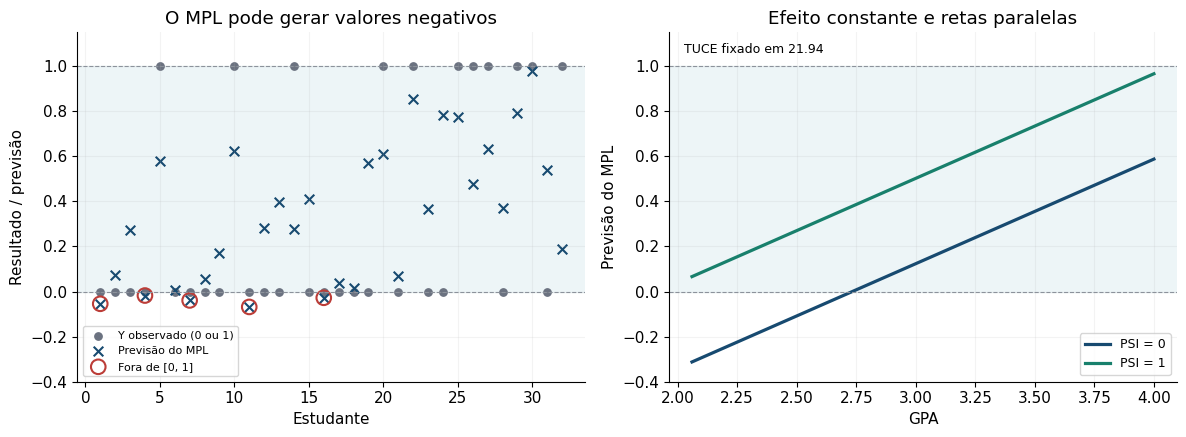

In [8]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))

# Painel 1: resultados observados e valores ajustados dos 32 estudantes.
ax = eixos[0]
ax.axhspan(0, 1, color="#edf5f7", zorder=0)
ax.scatter(dados.index, dados["Y"], color="#6b7280", s=28, label="Y observado (0 ou 1)")
ax.scatter(dados.index, dados["p_mpl"], color="#174a70", marker="x", s=48, label="Previsão do MPL")
ax.scatter(dados.index[fora_da_faixa], dados.loc[fora_da_faixa, "p_mpl"],
           facecolors="none", edgecolors="#bc3d38", s=110, linewidths=1.5,
           label="Fora de [0, 1]")
ax.set(xlabel="Estudante", ylabel="Resultado / previsão", title="O MPL pode gerar valores negativos")
ax.legend(fontsize=8, loc="lower left")

# Painel 2: perfis hipotéticos, mantendo TUCE na média amostral.
ax = eixos[1]
ax.axhspan(0, 1, color="#edf5f7", zorder=0)
grade_gpa = np.linspace(dados["GPA"].min(), dados["GPA"].max(), 100)
for psi, cor in [(0, "#174a70"), (1, "#18806c")]:
    grade = pd.DataFrame({"GPA": grade_gpa, "TUCE": dados["TUCE"].mean(), "PSI": psi})
    grade_X = sm.add_constant(grade[regressores], has_constant="add")
    ax.plot(grade_gpa, mpl.predict(grade_X), color=cor, linewidth=2.3, label=f"PSI = {psi}")
ax.set(xlabel="GPA", ylabel="Previsão do MPL", title="Efeito constante e retas paralelas")
ax.text(0.03, 0.94, f"TUCE fixado em {dados['TUCE'].mean():.2f}", transform=ax.transAxes, fontsize=9)
ax.legend(fontsize=9, loc="lower right")

for ax in eixos:
    ax.axhline(0, color="#8c929b", linestyle="--", linewidth=0.8)
    ax.axhline(1, color="#8c929b", linestyle="--", linewidth=0.8)
    ax.set_ylim(-0.4, 1.15)
    ax.grid(alpha=0.15)
fig.tight_layout()
plt.show()

**O que os gráficos mostram?** Nesta amostra há previsões negativas; não há previsões superiores a 1. No segundo painel, a inclinação é constante e a distância entre as retas é sempre a mesma. São características desta especificação linear, sem interações.

Substituir valores negativos por zero ou valores acima de 1 por um limita numericamente as previsões, mas não altera a especificação estimada nem resolve sua linearidade. Preservaremos os valores originais para compreender o problema.

## 4. Heterocedasticidade e erros padrão robustos · 35–40 min

Se a média condicional estiver corretamente especificada, $u_i=Y_i-p_i$. Para um mesmo conjunto de regressores, o erro assume dois valores: $1-p_i$, se $Y_i=1$, ou $-p_i$, se $Y_i=0$. Além disso:

$$\operatorname{Var}(u_i\mid X_i)=p_i(1-p_i).$$

Como essa variância geralmente varia com $X_i$, o MPL apresenta heterocedasticidade. A normalidade condicional do erro também não se aplica; ela não é necessária para calcular os coeficientes de MQO.

O capítulo menciona os erros padrão robustos de White. Usaremos a variante **HC1**, com ajuste por graus de liberdade. Os coeficientes e as previsões continuam os mesmos; mudam a matriz de covariância e a inferência. **A correção dos erros padrão não impede previsões fora de $[0,1]$.**

In [9]:
# HC1: erros padrão robustos à heterocedasticidade.
# use_t=True explicita a distribuição de referência usada neste exercício.
mpl_robusto = mpl.get_robustcov_results(cov_type="HC1", use_t=True)

comparacao_erros = pd.DataFrame({
    "Coeficiente MQO": mpl.params,
    "EP usual": mpl.bse,
    "EP robusto HC1": mpl_robusto.bse,
    "p-valor usual": mpl.pvalues,
    "p-valor com HC1": mpl_robusto.pvalues,
})
display(comparacao_erros.style.format("{:.4f}"))

,Coeficiente MQO,EP usual,EP robusto HC1,p-valor usual,p-valor com HC1
const,-1.4980,0.5239,0.4976,0.0079,0.0055
GPA,0.4639,0.1620,0.1511,0.0078,0.0047
TUCE,0.0105,0.0195,0.0174,0.5944,0.5515
PSI,0.3786,0.1392,0.1504,0.0111,0.0178


**Duas observações para interpretar a tabela:**

- Erros padrão robustos podem ser maiores ou menores que os usuais. Sua justificativa é acomodar a heterocedasticidade. A base tem apenas 32 observações: a inferência robusta é ilustrativa, e a referência t não torna os testes exatos nesta amostra.
- O $R^2$ de aproximadamente 0,416 é uma medida do ajuste da regressão. Ele não significa 41,6% de acertos na classificação nem uma probabilidade de 41,6%. Como discute o capítulo, não deve ser o único critério de avaliação.

## 5. Exercício prático em duplas · 40–55 min

**Integrantes:** escreva os nomes aqui.

Use o modelo já estimado e complete as três tarefas. Além de executar o código, registre a interpretação nas células **Sua resposta**. Use pontos percentuais quando comparar probabilidades.

| Tarefa | Tempo sugerido | Produto |
|---|---|---|
| A. Interpretar um coeficiente | 3 min | Uma frase com a unidade correta |
| B. Comparar três perfis | 7 min | Três previsões e duas diferenças |
| C. Alterar a especificação | 5 min | Uma nova estimação e uma comparação |

### A. Variação no GPA

Mantendo TUCE e PSI constantes, calcule a mudança prevista na probabilidade de obter A quando o GPA aumenta **0,5 ponto**. Complete o valor abaixo.

In [10]:
# Substitua None pela variação de GPA solicitada no enunciado.
variacao_gpa = None

if variacao_gpa is None:
    print("Preencha variacao_gpa e execute esta célula novamente.")
else:
    mudanca_pp = 100 * mpl.params["GPA"] * variacao_gpa
    print(f"Mudança prevista: {mudanca_pp:.2f} pontos percentuais.")

Preencha variacao_gpa e execute esta célula novamente.


**Sua resposta — A:** escreva uma frase que informe a variação de GPA, a mudança prevista e quais características foram mantidas constantes.

> Escreva aqui.

### B. Previsões para três perfis

Preencha os valores da célula de código usando a tabela:

| Perfil | GPA | TUCE | PSI |
|---|---:|---:|---:|
| A | 2,8 | 20 | 0 |
| B | 3,3 | 20 | 0 |
| C | 3,3 | 20 | 1 |

1. Calcule a previsão para cada perfil.
2. Calcule B − A e C − B, em pontos percentuais.
3. Relacione cada diferença com o coeficiente correspondente. Por que isso funciona no MPL estimado?

**No Python, use ponto decimal:** `2.8`, e não `2,8`.

In [11]:
# Preencha cada lista na ordem dos perfis A, B e C.
perfis_exercicio = pd.DataFrame({
    "GPA": [None, None, None],
    "TUCE": [None, None, None],
    "PSI": [None, None, None],
}, index=["A", "B", "C"])

if perfis_exercicio.isna().any().any():
    print("Preencha os nove valores dos perfis e execute esta célula novamente.")
else:
    X_exercicio = sm.add_constant(perfis_exercicio[regressores], has_constant="add")
    previsoes_exercicio = mpl.predict(X_exercicio)
    resultado_exercicio = perfis_exercicio.assign(p_mpl=previsoes_exercicio)
    display(resultado_exercicio.style.format({"GPA": "{:.1f}", "p_mpl": "{:.2%}"}))
    print(f"B − A: {100 * (previsoes_exercicio.loc['B'] - previsoes_exercicio.loc['A']):.2f} p.p.")
    print(f"C − B: {100 * (previsoes_exercicio.loc['C'] - previsoes_exercicio.loc['B']):.2f} p.p.")

Preencha os nove valores dos perfis e execute esta célula novamente.


**Sua resposta — B:** informe as três probabilidades previstas e interprete as duas diferenças. Explique por que B − A depende do coeficiente de GPA e C − B depende do coeficiente de PSI.

> Escreva aqui.

### C. Retirando um controle

Estime um novo MPL mantendo o intercepto, GPA e PSI, mas **retirando TUCE**. Complete a lista abaixo; observe como a construção da matriz $X$ e a estimação repetem os passos anteriores.

Compare o coeficiente de PSI no modelo completo e no modelo sem TUCE. Ele mudou muito nesta amostra? A comparação, isoladamente, permite concluir que retirar controles nunca altera a estimativa de PSI?

In [12]:
# Substitua None por uma lista com os nomes dos dois regressores solicitados.
# Sintaxe de uma lista: ["nome_da_variavel_1", "nome_da_variavel_2"]
regressores_exercicio = None

if regressores_exercicio is None:
    print("Preencha a lista de regressores e execute esta célula novamente.")
else:
    X_reduzido = sm.add_constant(dados[regressores_exercicio], has_constant="add")
    mpl_reduzido = sm.OLS(y, X_reduzido).fit(cov_type="HC1", use_t=True)
    comparacao_modelos = pd.DataFrame({
        "Modelo completo": [mpl.params["PSI"], mpl.rsquared],
        "Modelo sem TUCE": [mpl_reduzido.params["PSI"], mpl_reduzido.rsquared],
    }, index=["Coeficiente de PSI", "R²"])
    display(comparacao_modelos.style.format("{:.4f}"))
    diferenca_coef_pp = 100 * (mpl_reduzido.params["PSI"] - mpl.params["PSI"])
    print(f"Mudança no coeficiente de PSI, em p.p.: {diferenca_coef_pp:+.2f}")

Preencha a lista de regressores e execute esta célula novamente.


**Sua resposta — C:** compare os coeficientes de PSI e comente o que a comparação mostra sobre esta amostra.

> Escreva aqui.

## 6. Fechamento · 55–60 min

Discuta com a turma:

1. Por que $E(Y\mid X)$ pode ser interpretado como uma probabilidade quando $Y$ é binária?
2. O que a correção robusta dos erros padrão resolve? O que ela não resolve?
3. Que propriedade gostaríamos de garantir em um modelo de probabilidade, depois de observar as previsões negativas?

**Conclusão a registrar:** no MPL, os coeficientes oferecem uma interpretação direta das mudanças na probabilidade. A especificação impõe efeitos constantes e pode gerar valores ajustados fora de $[0,1]$; a heterocedasticidade exige atenção à inferência.

Na próxima aula, retomaremos a mesma base para estudar o modelo logit.

## Conferência após resolver o exercício

<details>
<summary><strong>Abrir respostas de referência</strong></summary>

**A.** Aumento de 0,5 ponto no GPA: mudança prevista de aproximadamente **23,19 pontos percentuais**, mantendo TUCE e PSI constantes. É uma associação ajustada no modelo.

**B.** Preencha GPA com `[2.8, 3.3, 3.3]`, TUCE com `[20, 20, 20]` e PSI com `[0, 0, 1]`.

| Perfil | Previsão do MPL |
|---|---:|
| A | 1,07% |
| B | 24,26% |
| C | 62,12% |

B − A é aproximadamente **23,19 p.p.**, porque apenas o GPA aumenta 0,5 ponto. C − B é aproximadamente **37,86 p.p.**, porque apenas PSI muda de 0 para 1. Nesta especificação aditiva, o efeito de cada regressor é constante.

**C.** Use `regressores_exercicio = ["GPA", "PSI"]`. O coeficiente de PSI passa de aproximadamente **0,3786** para **0,3865**, uma diferença de cerca de **0,79 ponto percentual**. O R² passa de aproximadamente 0,4159 para 0,4098. A mudança é pequena nesta amostra; isso não demonstra que controles sejam irrelevantes em geral nem estabelece causalidade.

**Diagnóstico do exemplo resolvido.** Há **5 previsões negativas e nenhuma superior a 1**. A menor previsão é aproximadamente −0,0682, e a maior é 0,9773. A correção HC1 preserva esses valores, pois não altera os coeficientes.

</details>

## Referências e relação com o livro

- **Gujarati, D. N.; Porter, D. C.** *Econometria básica*. 5. ed. Porto Alegre: AMGH, 2011. Capítulo 15. Fundamentos do MPL: seções 15.1–15.4, pp. 538–550; dados dos estudantes: Tabela 15.7, p. 559; referência para a estimação por MQO: Tabela 15.14, p. 567. Os erros padrão HC1 foram acrescentados para aplicar a discussão de heterocedasticidade do próprio capítulo.
- **Spector, L.; Mazzeo, M.** “Probit analysis and economic education.” *Journal of Economic Education*, v. 11, pp. 37–44, 1980. Fonte original dos dados, citada pelo livro.
- Documentação técnica: [base Spector no statsmodels](https://www.statsmodels.org/stable/datasets/generated/spector.html), [estimação por MQO](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLS.html) e [covariâncias robustas](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.get_robustcov_results.html).
- Abertura de arquivos `.ipynb`: [perguntas frequentes do Google Colab](https://research.google.com/colaboratory/faq.html).

As explicações e tarefas deste roteiro foram redigidas para a aula. Os números da base correspondem aos 32 estudantes do exemplo do livro; não são dados simulados.